<a href="https://colab.research.google.com/github/n-daiki0612/zemina-ru/blob/main/YoloLerning/Yolo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


#Yoloの概要
YOLO（You Only Look Once）は、画像や動画の中にある物体を検出するための深層学習モデルです。

Yoloを開発しているUltraLyiticsの公式サイトには
「物体検出、インスタンスセグメンテーション、セマンティックセグメンテーション、深度推定、分類、姿勢推定、回転バウンディングボックス、トラッキングに対応するリアルタイムコンピュータービジョンモデルのファミリーです。」（UltraLtycs公式サイトより）と記述してあります

もともとはJoseph Redmon氏が2016年に発表したYOLOv1がベースとなっており現在は主にUltralytics社が研究・開発したものが広く使われています.

下記のようにyoloのライブラリを用いることで簡単に実装することができます．

In [ ]:
!pip install -U ultralytics
from ultralytics import YOLO
model = YOLO("yolo26n.pt")  # 事前学習済みのYOLO26n検出モデルを読み込む
results = model("https://ultralytics.com/images/bus.jpg", save=True)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 6.5 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.

image 1/1 /content/bus.jpg: 640x480 4 persons, 1 bus, 396.6ms
Speed: 35.5ms preprocess, 396.6ms inference, 44.6ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict


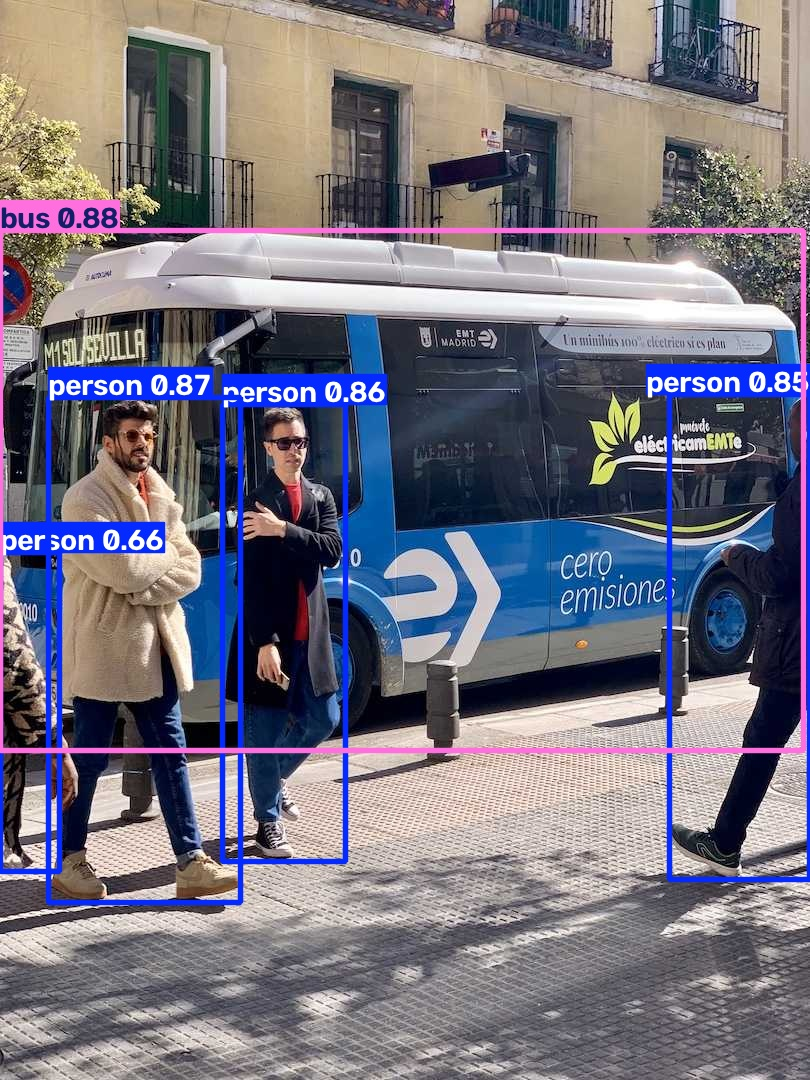

このように画像についてオブジェクトを検出しそのオブジェクトがどのクラスに何パーセントで属するのかについて検出することができます

#yoloのバージョンについて
現在主に使われているモデルは以下のようになっています\
・YoloV8\
・YoloV11\
・Yolo26

上記のバージョンはUltralitics社が開発したもの\
YoloにはUltralitics社が開発したものと大学等の研究者が開発したものがあります．




# YOLOのアルゴリズム
初代YOLO（YOLOv1）を例に、画像から物体を検出するまでの仕組みを見ていきます。

YOLOでは大きくわけると以下の3つの処理を行っています

1. **特徴抽出**：CNNを使って画像から特徴を取り出します。

2. **予測**：取り出した特徴から物体の位置や種類を予測します。

3. **検出結果の整理**：信頼度の低い予測や重複する予測を取り除きます。



## 1. CNNによる特徴抽出（Backbone）

まず、入力画像をCNN（畳み込みニューラルネットワーク）に入力します。

CNNは、画像の特徴を取り出すためのニューラルネットワークです。

主に次の処理を組み合わせて特徴を抽出します。

- **畳み込み（Convolution）**：画像にフィルタを適用し、輪郭や模様などの特徴を取り出します。
- **プーリング（Pooling）**：特徴マップのサイズを小さくし、情報をまとめます。



# 畳み込み

畳み込みでは、画像の上で小さなフィルタを少しずつ動かし、画像とフィルタの数値を掛け合わせて足し合わせます。

1チャネル、Stride 1、Paddingなしの場合、次の式で表せます。

$
Y(i,j)=\sum_{m=0}^{K-1}\sum_{n=0}^{K-1}
X(i+m,j+n)W(m,n)
$

ここで、

- \(X\)：入力画像
- \(W\)：フィルタ
- \(K\)：フィルタのサイズ
- \(Y\)：出力される特徴マップ

を表します。

なお、実際のCNNではフィルタの重みは学習によって決まります。


In [2]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
from matplotlib.patches import Rectangle

# 説明用の6×6画像
image = np.array([
    [0, 0, 1, 1, 0, 0],
    [0, 0, 1, 1, 0, 0],
    [0, 0, 1, 1, 0, 0],
    [0, 0, 1, 1, 0, 0],
    [0, 0, 1, 1, 0, 0],
    [0, 0, 1, 1, 0, 0]
])

# 縦方向の境界を強調するフィルタ
kernel = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
])

kh, kw = kernel.shape
out_h = image.shape[0] - kh + 1
out_w = image.shape[1] - kw + 1

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

def draw_array(ax, arr, title, vmin=None, vmax=None):
    ax.clear()
    ax.imshow(arr, cmap="coolwarm", vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xticks(range(arr.shape[1]))
    ax.set_yticks(range(arr.shape[0]))

    for y in range(arr.shape[0]):
        for x in range(arr.shape[1]):
            val = arr[y, x]
            if np.isfinite(val):
                ax.text(x, y, f"{val:.0f}",
                        ha="center", va="center", fontsize=12)

def update(frame):
    # 計算する出力位置
    y = frame // out_w
    x = frame % out_w

    # 現在のフィルタ位置
    region = image[y:y+kh, x:x+kw]
    result = np.sum(region * kernel)

    # ここまでの計算結果
    output = np.full((out_h, out_w), np.nan)

    for n in range(frame + 1):
        i = n // out_w
        j = n % out_w
        patch = image[i:i+kh, j:j+kw]
        output[i, j] = np.sum(patch * kernel)

    # 入力画像
    draw_array(axes[0], image, "Input Image")
    axes[0].add_patch(
        Rectangle(
            (x-0.5, y-0.5), kw, kh,
            fill=False, edgecolor="red", linewidth=3
        )
    )

    # フィルタ
    draw_array(axes[1], kernel, "3x3 Filter")

    # 出力特徴マップ
    draw_array(
        axes[2], output,
        "Feature Map",
        vmin=-3, vmax=3
    )

    axes[2].add_patch(
        Rectangle(
            (x-0.5, y-0.5), 1, 1,
            fill=False, edgecolor="green", linewidth=3
        )
    )

    fig.suptitle(
        f"Step {frame+1}/{out_h*out_w}  "
        f"Multiply and Sum = {result:.0f}",
        fontsize=14
    )

animation = FuncAnimation(
    fig,
    update,
    frames=out_h * out_w,
    interval=700,
    repeat=True
)

plt.close(fig)
display(HTML(animation.to_jshtml()))


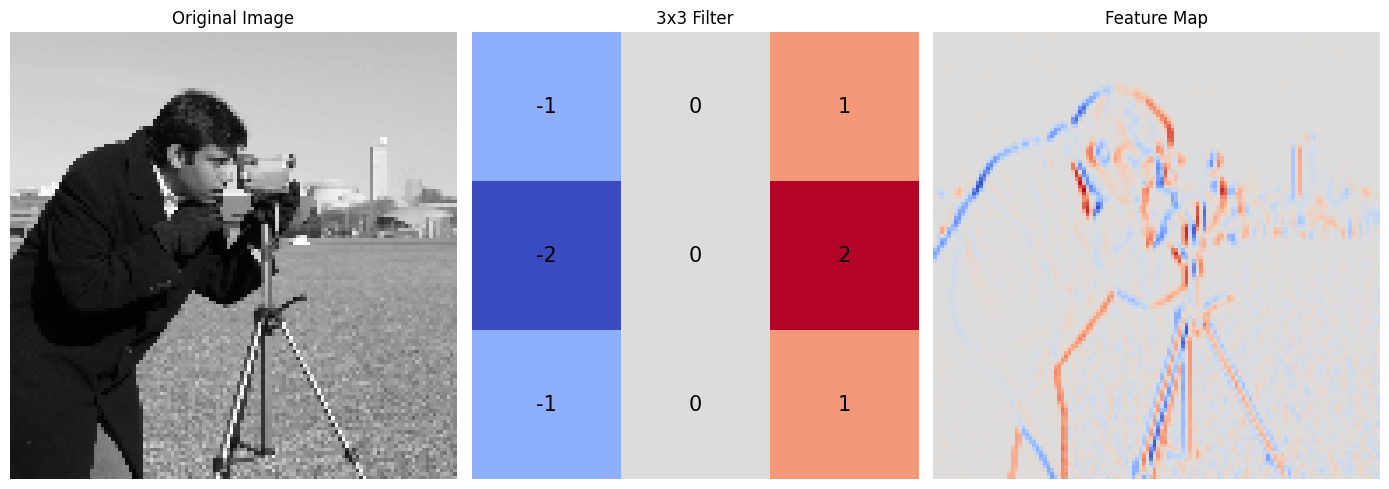

入力画像: (128, 128)
フィルタ: (3, 3)
特徴マップ: (126, 126)


In [3]:

import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# 実際の写真を読み込む
image = data.camera().astype(float)

# 計算を軽くするため128×128に縮小
image = image[::4, ::4]

# 縦方向の境界を強調する3×3フィルタ
kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=float)

# 1層の畳み込み
def convolution2d(img, kernel):
    h, w = img.shape
    kh, kw = kernel.shape

    result = np.zeros((h-kh+1, w-kw+1))

    for i in range(result.shape[0]):
        for j in range(result.shape[1]):
            region = img[i:i+kh, j:j+kw]
            result[i, j] = np.sum(region * kernel)

    return result

feature_map = convolution2d(image, kernel)

# 結果を表示
fig, axes = plt.subplots(1, 3, figsize=(14, 5))

axes[0].imshow(image, cmap="gray")
axes[0].set_title("Original Image")

axes[1].imshow(kernel, cmap="coolwarm")
axes[1].set_title("3x3 Filter")

for i in range(3):
    for j in range(3):
        axes[1].text(
            j, i, f"{kernel[i,j]:.0f}",
            ha="center", va="center",
            fontsize=15
        )

# 正と負の変化を区別できるように表示
scale = np.max(np.abs(feature_map))

axes[2].imshow(
    feature_map,
    cmap="coolwarm",
    vmin=-scale,
    vmax=scale
)
axes[2].set_title("Feature Map")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("入力画像:", image.shape)
print("フィルタ:", kernel.shape)
print("特徴マップ:", feature_map.shape)


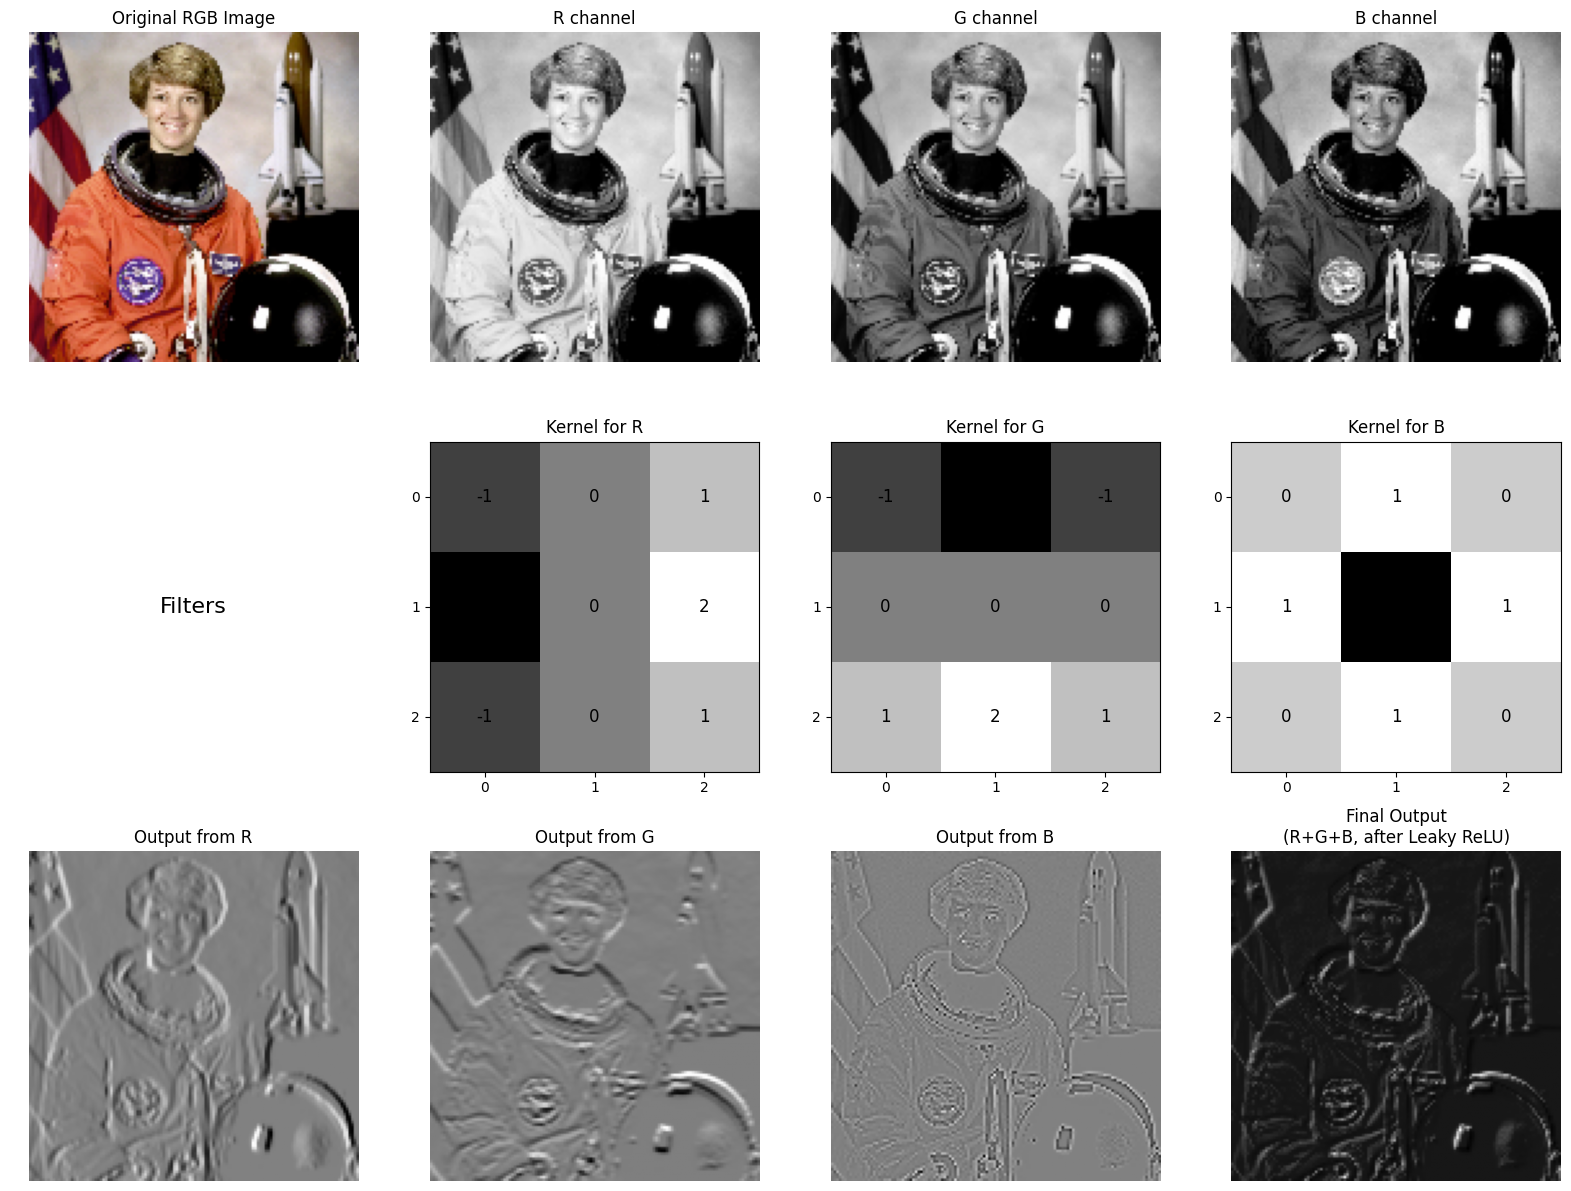

入力画像の形状: (128, 128, 3)
Rチャネル出力: (126, 126)
Gチャネル出力: (126, 126)
Bチャネル出力: (126, 126)
最終出力: (126, 126)


In [4]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# -----------------------------------
# 1. カラー画像を読み込む
# -----------------------------------
image = data.astronaut().astype(float) / 255.0  # 0〜1に正規化

# 計算量を減らすために少し縮小
image = image[::4, ::4, :]   # 128×128程度

# RGBチャネルに分ける
R = image[:, :, 0]
G = image[:, :, 1]
B = image[:, :, 2]

# -----------------------------------
# 2. 畳み込み用の関数
# -----------------------------------
def conv2d(img, kernel):
    h, w = img.shape
    kh, kw = kernel.shape
    out = np.zeros((h - kh + 1, w - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            region = img[i:i+kh, j:j+kw]
            out[i, j] = np.sum(region * kernel)
    return out

# -----------------------------------
# 3. RGBそれぞれに対応するフィルタ
#    （本来は学習で決まるが、ここでは説明用）
# -----------------------------------
kernel_R = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=float)

kernel_G = np.array([
    [-1, -2, -1],
    [ 0,  0,  0],
    [ 1,  2,  1]
], dtype=float)

kernel_B = np.array([
    [ 0,  1,  0],
    [ 1, -4,  1],
    [ 0,  1,  0]
], dtype=float)

# -----------------------------------
# 4. 各チャネルに畳み込みを適用
# -----------------------------------
out_R = conv2d(R, kernel_R)
out_G = conv2d(G, kernel_G)
out_B = conv2d(B, kernel_B)

# 実際のCNNに近い最終出力（足し合わせる）
out_sum = out_R + out_G + out_B

# YOLOv1では活性化関数としてLeaky ReLUが使われるので、
# それに近い形も見せる
alpha = 0.1
out_leaky = np.where(out_sum > 0, out_sum, alpha * out_sum)

# 表示用にスケールを揃える
def normalize_for_display(x):
    x_min = x.min()
    x_max = x.max()
    if x_max - x_min < 1e-8:
        return np.zeros_like(x)
    return (x - x_min) / (x_max - x_min)

# -----------------------------------
# 5. 可視化
# -----------------------------------
fig, axes = plt.subplots(3, 4, figsize=(16, 12))

# 1行目：元画像とRGBチャネル
axes[0, 0].imshow(image)
axes[0, 0].set_title("Original RGB Image")
axes[0, 0].axis("off")

axes[0, 1].imshow(R, cmap="gray")
axes[0, 1].set_title("R channel")
axes[0, 1].axis("off")

axes[0, 2].imshow(G, cmap="gray")
axes[0, 2].set_title("G channel")
axes[0, 2].axis("off")

axes[0, 3].imshow(B, cmap="gray")
axes[0, 3].set_title("B channel")
axes[0, 3].axis("off")

# 2行目：各チャネルのフィルタ
kernel_list = [kernel_R, kernel_G, kernel_B]
kernel_titles = ["Kernel for R", "Kernel for G", "Kernel for B"]

axes[1, 0].axis("off")
axes[1, 0].text(0.5, 0.5, "Filters", ha="center", va="center", fontsize=16)

for idx, (k, title) in enumerate(zip(kernel_list, kernel_titles), start=1):
    axes[1, idx].imshow(k, cmap="gray")
    axes[1, idx].set_title(title)
    axes[1, idx].set_xticks(range(3))
    axes[1, idx].set_yticks(range(3))
    for y in range(3):
        for x in range(3):
            axes[1, idx].text(x, y, f"{k[y, x]:.0f}",
                              ha="center", va="center", fontsize=12)

# 3行目：各チャネルの出力と最終出力
axes[2, 0].imshow(normalize_for_display(out_R), cmap="gray")
axes[2, 0].set_title("Output from R")
axes[2, 0].axis("off")

axes[2, 1].imshow(normalize_for_display(out_G), cmap="gray")
axes[2, 1].set_title("Output from G")
axes[2, 1].axis("off")

axes[2, 2].imshow(normalize_for_display(out_B), cmap="gray")
axes[2, 2].set_title("Output from B")
axes[2, 2].axis("off")

axes[2, 3].imshow(normalize_for_display(out_leaky), cmap="gray")
axes[2, 3].set_title("Final Output\n(R+G+B, after Leaky ReLU)")
axes[2, 3].axis("off")

plt.tight_layout()
plt.show()

print("入力画像の形状:", image.shape)
print("Rチャネル出力:", out_R.shape)
print("Gチャネル出力:", out_G.shape)
print("Bチャネル出力:", out_B.shape)
print("最終出力:", out_leaky.shape)

先ほどのコードでは、6×6の画像に3×3のフィルタを適用しました。

緑色の枠で囲まれた部分とフィルタの値を掛け合わせ、その合計を特徴マップの1つの値としています。

この計算をフィルタの位置をずらしながら繰り返すことで、新しい特徴マップが作られます。

今回の例では、画像の縦方向の境界を強調するフィルタを使用しました。

実際のCNNでは、さまざまなフィルタを使って複数の特徴マップを作ります。



#プーリング層

CNNでは、畳み込みだけでなくプーリングも使用します。

例えば、Max Poolingでは2×2の範囲から最も大きな値を取り出します。


\begin{bmatrix}
1 & 3\\
2 & 4
\end{bmatrix}

この場合だと4という数値を取り出しまあす


2×2、Stride 2のMax Poolingを使うと、特徴マップの縦横サイズを半分にできます。

こうした処理を繰り返すことで、画像のサイズを小さくしながら特徴を抽出していきます。


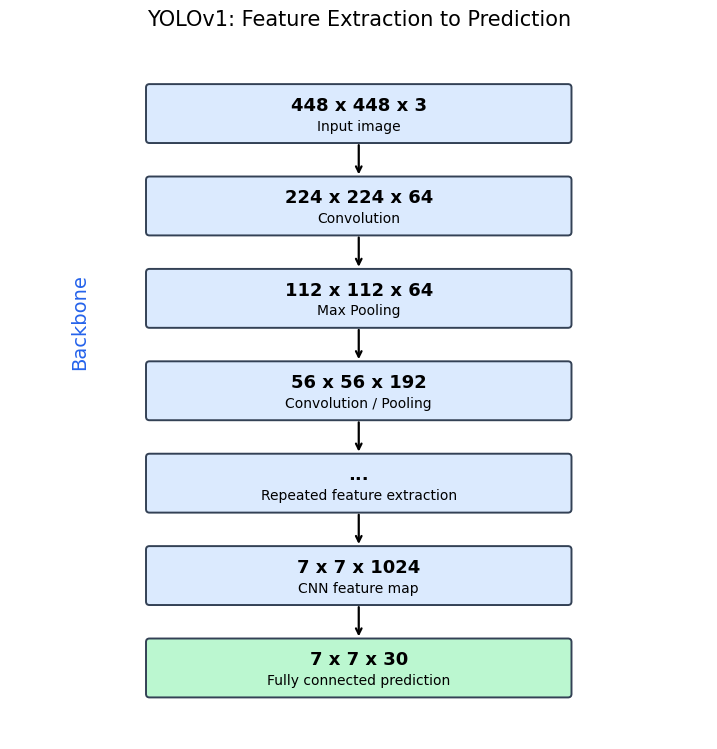

In [5]:

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(9, 9))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis("off")

stages = [
    ("448 x 448 x 3", "Input image"),
    ("224 x 224 x 64", "Convolution"),
    ("112 x 112 x 64", "Max Pooling"),
    ("56 x 56 x 192", "Convolution / Pooling"),
    ("...", "Repeated feature extraction"),
    ("7 x 7 x 1024", "CNN feature map"),
    ("7 x 7 x 30", "Fully connected prediction")
]

ys = np.linspace(9.0, 1.0, len(stages))

for i, ((shape, label), y) in enumerate(zip(stages, ys)):
    color = "#dbeafe" if i < 6 else "#bbf7d0"

    rect = FancyBboxPatch(
        (2.0, y-0.35), 6.0, 0.75,
        boxstyle="round,pad=0.05",
        facecolor=color,
        edgecolor="#334155",
        linewidth=1.4
    )
    ax.add_patch(rect)

    ax.text(5, y+0.15, shape,
            ha="center", va="center",
            fontsize=13, weight="bold")
    ax.text(5, y-0.15, label,
            ha="center", va="center",
            fontsize=10)

    if i < len(stages)-1:
        ax.annotate(
            "", xy=(5, ys[i+1]+0.44),
            xytext=(5, y-0.39),
            arrowprops=dict(arrowstyle="->", lw=1.6)
        )

ax.text(1.0, 5.4, "Backbone",
        rotation=90, fontsize=14,
        color="#2563eb", ha="center")

ax.set_title("YOLOv1: Feature Extraction to Prediction",
             fontsize=15, pad=15)

plt.show()



### Backboneによる特徴抽出のまとめ

初代YOLOでは、448×448の入力画像に対して畳み込みやプーリングを繰り返します。

$
448\times448\times3
\xrightarrow{\mathrm{CNN}}
7\times7\times1024
$

畳み込みやプーリングによって縦横のサイズを小さくしながら、複数のフィルタを使って特徴を抽出していきます。

ここで、特徴マップの3つ目の数字は**チャネル数**を表しています。

チャネルは、それぞれ異なる特徴を表すための情報です。

このように、画像から特徴を抽出する部分を**Backbone（バックボーン）**と呼びます。

その後、初代YOLOでは全結合層を通して、物体検出に必要な情報を予測します。




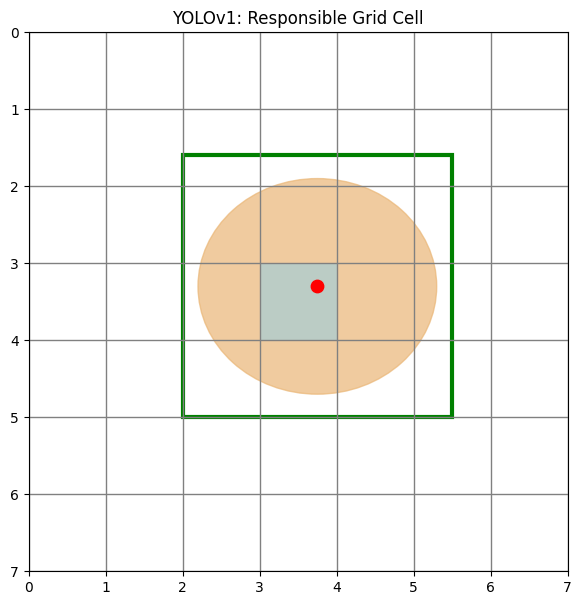

物体の中心: (3.75, 3.3)
担当セル: (3, 3)


In [6]:

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Ellipse

fig, ax = plt.subplots(figsize=(7, 7))

ax.set_xlim(0, 7)
ax.set_ylim(7, 0)
ax.set_aspect("equal")

# 物体の模式図
object_box = (2.0, 1.6, 3.5, 3.4)
x, y, w, h = object_box

ax.add_patch(Ellipse(
    (x+w/2, y+h/2), 3.1, 2.8,
    color="#eab676", alpha=0.7
))

# 物体を囲むBounding Box
ax.add_patch(Rectangle(
    (x, y), w, h,
    fill=False, edgecolor="green",
    linewidth=3
))

# 物体の中心
cx = x + w/2
cy = y + h/2

# 中心が含まれるセル
cell_x = int(cx)
cell_y = int(cy)

ax.add_patch(Rectangle(
    (cell_x, cell_y), 1, 1,
    facecolor="skyblue", alpha=0.5
))

# グリッドの線
for i in range(8):
    ax.axvline(i, color="gray", linewidth=1)
    ax.axhline(i, color="gray", linewidth=1)

ax.scatter(cx, cy, color="red", s=80, zorder=5)

ax.set_xticks(range(8))
ax.set_yticks(range(8))
ax.set_title("YOLOv1: Responsible Grid Cell")

plt.show()

print("物体の中心:", (cx, cy))
print("担当セル:", (cell_y, cell_x))



物体の位置と種類の予測

CNNによって取り出した特徴は、全結合層を通して検出結果の予測に変換されます。

初代YOLOの最終的な出力は、次の形になります。

$
7\times7\times30
$

これは49個のセルそれぞれが30個の数値を予測するという意味です。

| 予測する情報 | 数値の数 |
|---|---:|
| Bounding Box 1 | 5 |
| Bounding Box 2 | 5 |
| クラス確率 | 20 |
| 合計 | 30 |


### Bounding Boxについて

Bounding Boxは、物体を囲む四角形のことです。

各Bounding Boxについて、次の5つの値を予測します。

$
(x,y,w,h,\mathrm{Confidence})
$

- \(x,y\)：Bounding Boxの中心座標
- \(w,h\)：Bounding Boxの幅と高さ
- \(\mathrm{Confidence}\)：予測の信頼度

### クラス確率について

さらに、各セルは20種類のクラスについて、それぞれの条件付き確率を予測します。

例えば、犬75%、猫15%、人10%といった予測結果が得られます。

なお、初代YOLOでは2つのBounding Boxが同じ20個のクラス確率を共有しています。

また、物体が存在しない場合は、学習によってBounding BoxのConfidenceが低くなるようになっています。



## 4. クラス確率とConfidenceを使った判定

YOLOでは、クラスの確率だけでなく、Bounding BoxのConfidenceも使って検出結果を判断します。

初代YOLOでは、Confidenceは次のように定義されています。

$
\mathrm{Confidence}
=
P(\mathrm{Object})\times\mathrm{IoU}
$

ここでIoUは、予測したBounding Boxと正解のBounding Boxがどれくらい重なっているかを表す指標です。

推論時には正解のBounding Boxが分からないため、ニューラルネットワークが予測したConfidenceを使用します。

そして、クラスごとの検出スコアを次のように計算します。

$
\mathrm{Score}_i
=
P(\mathrm{Class}_i\mid\mathrm{Object})
\times\mathrm{Confidence}
$

例えば、

$
P(\mathrm{Dog}\mid\mathrm{Object})=0.75
$

$
\mathrm{Confidence}=0.80
$

だった場合、

$
\mathrm{Score}_{\mathrm{Dog}}
=0.75\times0.80=0.60
$

となります。

このスコアを使って信頼度の低い候補を取り除き、NMS（Non-Maximum Suppression）によって重複したBounding Boxを整理します。



### 実際の画像でYOLOの検出結果を確認してみましょう

ここまで、物体の種類を表すクラス確率と、Bounding Boxの信頼度について説明しました。

今回は、実際の画像を学習済みYOLOに入力して、物体がどのように検出されるかを確認します。

画像から物体を検出すると、次のような情報が得られます。

- **Bounding Box**：物体が存在する位置
- **クラス**：検出した物体の種類
- **検出スコア**：その物体の検出がどの程度確からしいかを表す値

今回は、新しいYOLOモデルを使って実際の検出結果を確認します。

初代YOLOでは、クラス確率とConfidenceを掛け合わせて検出スコアを計算していましたが、現在のYOLOではその計算方法が異なります

## 4. クラス確率とConfidenceを使った判定

ここでは、実際の画像を使って、YOLOv1で行われる  
**「クラス確率 × Confidence」** の考え方を確認します。

今回は、画像の中にある1つの物体に対して、2つのBounding Boxが予測されたと仮定します。

それぞれのBounding Boxについて、

- そのクラスである確率  
- Bounding BoxのConfidence  

を設定し、次の式で検出スコアを計算します。

$
\mathrm{Score}_i
=
P(\mathrm{Class}_i \mid \mathrm{Object})
\times
\mathrm{Confidence}
$

例えば、同じ「cat」というクラスを予測していても、  
Bounding Boxの位置や信頼度が異なれば、最終的なスコアも変わります。

このようにして、YOLOでは物体の種類だけでなく、  
そのBounding Boxがどれくらい信頼できるかもあわせて評価します。

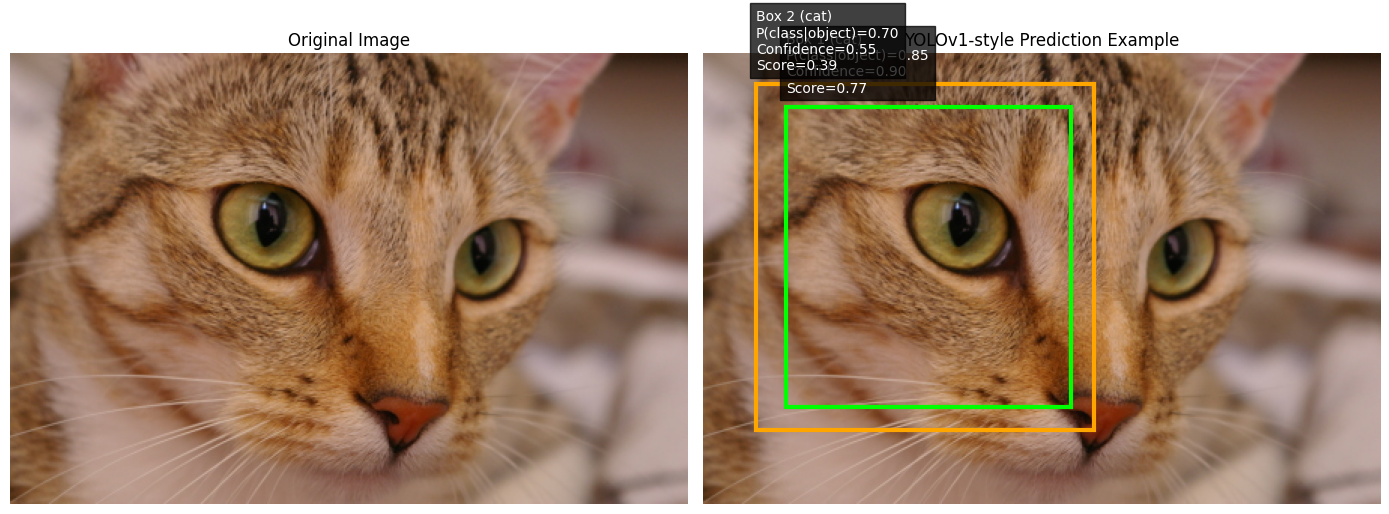

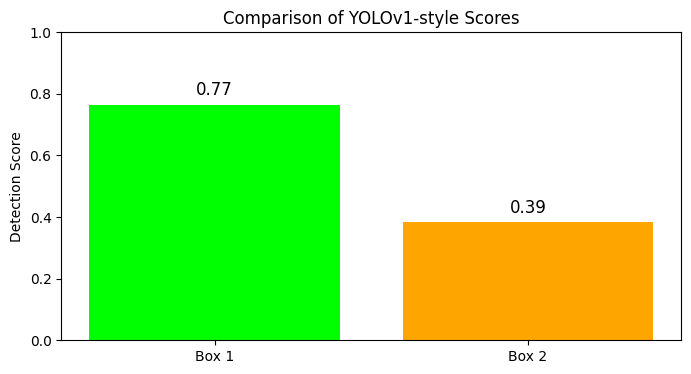

Box 1:
  class = cat
  P(class|object) = 0.85
  Confidence      = 0.90
  Score           = 0.77

Box 2:
  class = cat
  P(class|object) = 0.70
  Confidence      = 0.55
  Score           = 0.39

最終的により信頼できるBounding Boxとして選ばれやすいのは:
Box 1  （Score = 0.77）


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from skimage import data

# -----------------------------------
# 1. 実際の画像を読み込む
# -----------------------------------
image = data.chelsea()   # 猫の画像

# -----------------------------------
# 2. YOLOv1風の仮の予測結果を用意する
#    ここでは同じ「cat」を予測した2つのBoxを想定
# -----------------------------------
boxes = [
    {
        "label": "Box 1",
        "class_name": "cat",
        "x1": 55,
        "y1": 35,
        "x2": 245,
        "y2": 235,
        "class_prob": 0.85,   # P(cat | object)
        "confidence": 0.90,   # Confidence
        "color": "lime"
    },
    {
        "label": "Box 2",
        "class_name": "cat",
        "x1": 35,
        "y1": 20,
        "x2": 260,
        "y2": 250,
        "class_prob": 0.70,   # P(cat | object)
        "confidence": 0.55,   # Confidence
        "color": "orange"
    }
]

# スコア計算
for box in boxes:
    box["score"] = box["class_prob"] * box["confidence"]

# -----------------------------------
# 3. 画像上にBounding Boxを描画
# -----------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 左：元画像
axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

# 右：仮のYOLOv1予測結果
axes[1].imshow(image)
axes[1].set_title("YOLOv1-style Prediction Example")
axes[1].axis("off")

for box in boxes:
    x1, y1, x2, y2 = box["x1"], box["y1"], box["x2"], box["y2"]
    w, h = x2 - x1, y2 - y1

    rect = Rectangle(
        (x1, y1), w, h,
        fill=False,
        edgecolor=box["color"],
        linewidth=3
    )
    axes[1].add_patch(rect)

    text = (
        f"{box['label']} ({box['class_name']})\n"
        f"P(class|object)={box['class_prob']:.2f}\n"
        f"Confidence={box['confidence']:.2f}\n"
        f"Score={box['score']:.2f}"
    )

    axes[1].text(
        x1,
        max(5, y1 - 10),
        text,
        color="white",
        fontsize=10,
        bbox=dict(facecolor="black", alpha=0.75)
    )

plt.tight_layout()
plt.show()

# -----------------------------------
# 4. スコアを棒グラフで比較
# -----------------------------------
labels = [box["label"] for box in boxes]
scores = [box["score"] for box in boxes]
colors = [box["color"] for box in boxes]

plt.figure(figsize=(8, 4))
plt.bar(labels, scores, color=colors)
plt.ylim(0, 1)
plt.ylabel("Detection Score")
plt.title("Comparison of YOLOv1-style Scores")
for i, score in enumerate(scores):
    plt.text(i, score + 0.03, f"{score:.2f}", ha="center", fontsize=12)
plt.show()

# -----------------------------------
# 5. 計算結果を表示
# -----------------------------------
for box in boxes:
    print(f"{box['label']}:")
    print(f"  class = {box['class_name']}")
    print(f"  P(class|object) = {box['class_prob']:.2f}")
    print(f"  Confidence      = {box['confidence']:.2f}")
    print(f"  Score           = {box['score']:.2f}")
    print()

best_box = max(boxes, key=lambda b: b["score"])
print("最終的により信頼できるBounding Boxとして選ばれやすいのは:")
print(f"{best_box['label']}  （Score = {best_box['score']:.2f}）")


## NMSによる重複の除去

YOLOでは、1つの物体に対して複数のBounding Boxが予測されることがあります。

そこで、**NMS（Non-Maximum Suppression）**という方法を使い、重複したBounding Boxを取り除きます。

NMSでは、まず検出スコアが最も高いBounding Boxを選びます。

次に、そのBounding Boxとほかの候補の重なり具合をIoUによって計算します。

$
\mathrm{IoU}=
\frac{\text{2つのBoxの共通部分の面積}}
{\text{2つのBoxの和集合の面積}}
$

同じクラスについて、IoUが設定した閾値を超える候補を取り除きます。

この処理を繰り返すことで、同じ物体に対する重複した検出を減らすことができました

まず物体の位置や種類を予測し、その後NMSを使って検出結果を整理しています。


#yoloのバージョンについて
現在主に使われているモデルは以下のようになっています\
・YoloV8\
・YoloV11\
・Yolo26

上記のバージョンはUltralitics社が開発したもの\
YoloにはUltralitics社が開発したものと大学等の研究者が開発したものがあります．

- YOLOv8：Bounding Boxの予測方法を改良
- YOLO11：特徴抽出の効率を改善
- YOLO26：予測・後処理・学習方法をさらに改善\
といった特徴があるので必要なバージョンを適切に使うことが大切です

